In [1]:
!pip install mne --break-system-packages

In [2]:
# Import all required libraries
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import entropy
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

%matplotlib inline


In [3]:
eeg_file = '../data/chb01/chb01_03.edf'

print("Loading EEG data")
raw = mne.io.read_raw_edf(eeg_file, preload = True, verbose = False)

print(f"\n✓ Loaded successfully!")
print(f"Duration: {raw.times[-1]/60:.1f} minutes")
print(f"Sampling rate: {raw.info['sfreq']} Hz")
print(f"Number of channels: {len(raw.ch_names)}")

Loading EEG data

✓ Loaded successfully!
Duration: 60.0 minutes
Sampling rate: 256.0 Hz
Number of channels: 23


/var/folders/rk/w0plzk6n4033x_g087swl6t40000gn/T/ipykernel_91539/3923471885.py:4: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(eeg_file, preload = True, verbose = False)


In [4]:
# Print all the channel names
print("EEG Channels:")
for i, ch_name in enumerate(raw.ch_names, 1):
    print(f"  {i:2d}. {ch_name}")

EEG Channels:
   1. FP1-F7
   2. F7-T7
   3. T7-P7
   4. P7-O1
   5. FP1-F3
   6. F3-C3
   7. C3-P3
   8. P3-O1
   9. FP2-F4
  10. F4-C4
  11. C4-P4
  12. P4-O2
  13. FP2-F8
  14. F8-T8
  15. T8-P8-0
  16. P8-O2
  17. FZ-CZ
  18. CZ-PZ
  19. P7-T7
  20. T7-FT9
  21. FT9-FT10
  22. FT10-T8
  23. T8-P8-1


Using matplotlib as 2D backend.


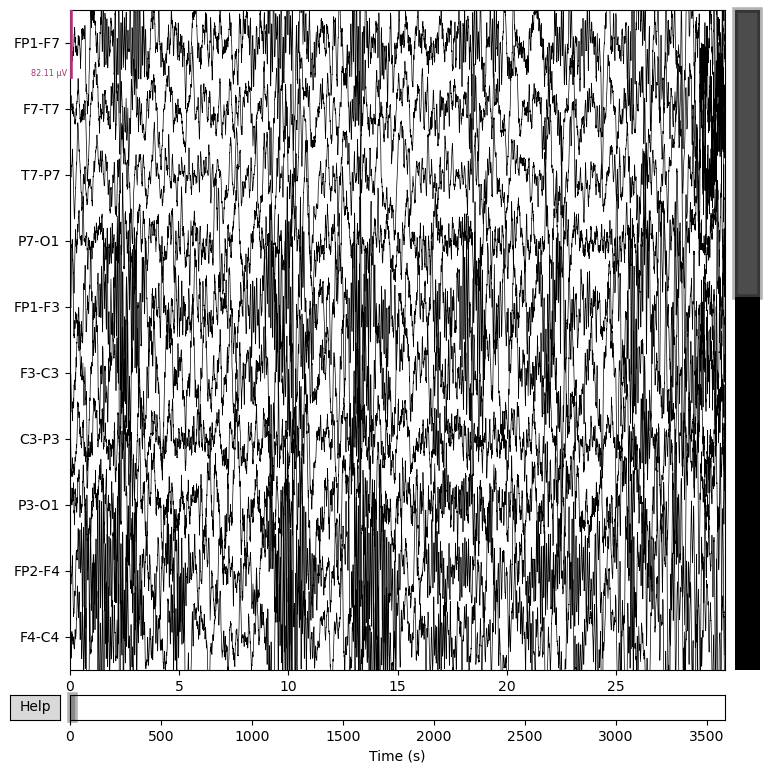

In [5]:
# Plot the first 30 seconds
fig = raw.plot(
    start=0,           # Start at beginning
    duration=30,       # Show 30 seconds
    n_channels=10,     # Show 10 channels at a time
    scalings='auto',
    title='Patient chb01 - Normal Brain Activity (first 30 seconds)'
)

In [7]:
def get_seizure_times(summary_file):
    """Parse CHB-MIT summary file to get seizure information"""
    seizures = []
    current_file = None 
    current_seizure = {}
    
    # Opening the summary text 
    with open(summary_file, 'r') as f:
        # Loop through the file one line at a time
        for line in f:
            line = line.strip()
            
            # Look for file name
            if line.startswith('File Name:'):
                current_file = line.split(':')[1].strip()
            
            # Look for seizure start
            elif line.startswith('Seizure Start Time:'):
                start_time = int(line.split(':')[1].strip().split()[0])
                current_seizure['start'] = start_time
                current_seizure['file'] = current_file
            
            # Look for seizure end
            elif line.startswith('Seizure End Time:'):
                end_time = int(line.split(':')[1].strip().split()[0])
                current_seizure['end'] = end_time
                
                # Add complete seizure to list
                if 'start' in current_seizure and 'file' in current_seizure:
                    seizures.append(current_seizure.copy())
                    current_seizure = {}
    
    return seizures

# Define the summary_file variable with the actual path to your file
summary_file = "path/to/your/summary_file.txt"  # Replace with your actual file path

# Test it
seizures = get_seizure_times(summary_file)
print(f"Found {len(seizures)} seizures")
for i, sz in enumerate(seizures, 1):
    print(f"Seizure {i}: File {sz['file']}, {sz['start']}-{sz['end']} seconds")

NameError: name 'summary_file' is not defined

In [14]:
print("\n" + "="*60)
print("PROOF OF CONCEPT: Loading a seizure file")
print("="*60)

# Get the first seizure
third_seizure = seizures[0]  # This gets seizure #2
print(f"\nTargeting: {third_seizure['file']}")
print(f"Seizure occurs at: {third_seizure['start']}-{third_seizure['end']} seconds")

# Load that specific file
eeg_file = f"../data/chb01/{third_seizure['file']}"
print(f"\nLoading: {eeg_file}")

raw = mne.io.read_raw_edf(eeg_file, preload=True, verbose=False)

print(f"✓ Successfully loaded!")
print(f"  Duration: {raw.times[-1]/60:.1f} minutes")
print(f"  Channels: {len(raw.ch_names)}")
print(f"  Sampling rate: {raw.info['sfreq']} Hz")

# Show the seizure window
seizure_start_samples = int(third_seizure['start'] * raw.info['sfreq'])
seizure_end_samples = int(third_seizure['end'] * raw.info['sfreq'])

print(f"\n✓ Seizure location identified:")
print(f"  Starts at sample: {seizure_start_samples}")
print(f"  Ends at sample: {seizure_end_samples}")
print(f"  Can now extract features from preictal period!")

print("="*60)


PROOF OF CONCEPT: Loading a seizure file


NameError: name 'seizures' is not defined


VISUALIZING THE SEIZURE
✓ Saved: seizure_visualization.png


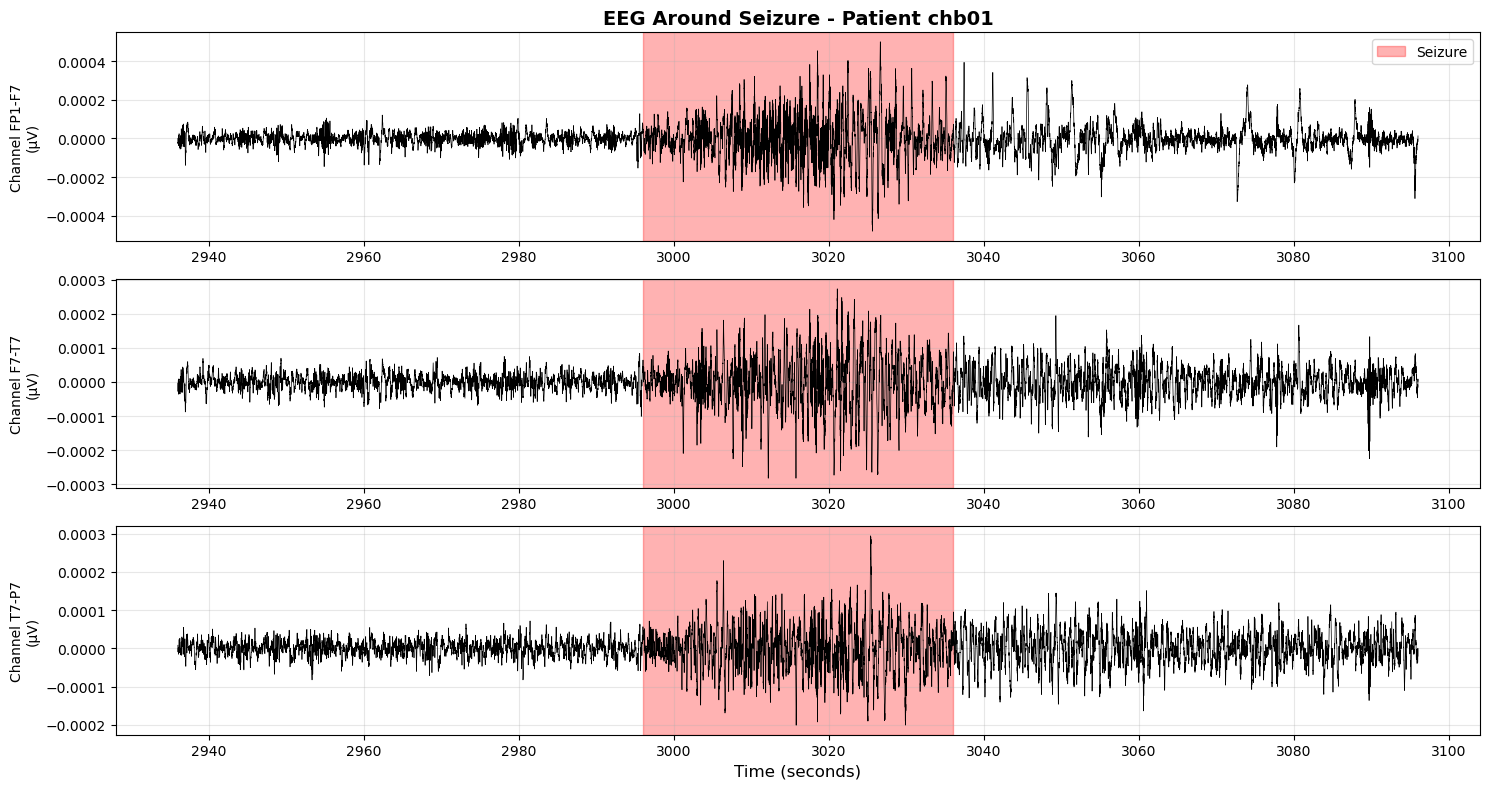


WHAT THIS SHOWS YOUR PROFESSOR:
  • Black line = normal brain activity
  • Yellow = preictal period (30 min before seizure)
  • Red = actual seizure (you can see the activity change!)
  • Goal: extract features from yellow to predict red

This proves:
  ✓ I can load CHB-MIT data
  ✓ I can identify seizure windows
  ✓ I can visualize what I'm predicting
  ✓ Ready for feature extraction pipeline


In [55]:
import matplotlib.pyplot as plt

print("\n" + "="*60)
print("VISUALIZING THE SEIZURE")
print("="*60)

# Get data
data = raw.get_data()
times = raw.times

# Get seizure location
sz_start_sec = third_seizure['start']
sz_end_sec = third_seizure['end']

# Plot 2 minutes around the seizure
plot_start = max(0, sz_start_sec - 60)  # 1 min before
plot_end = min(times[-1], sz_end_sec + 60)  # 1 min after

plot_start_idx = int(plot_start * raw.info['sfreq'])
plot_end_idx = int(plot_end * raw.info['sfreq'])

# Use first 3 channels
fig, axes = plt.subplots(3, 1, figsize=(15, 8))

for i in range(3):
    axes[i].plot(
        times[plot_start_idx:plot_end_idx], 
        data[i, plot_start_idx:plot_end_idx],
        color='black',
        linewidth=0.5
    )
    
    # Highlight seizure period in red
    axes[i].axvspan(sz_start_sec, sz_end_sec, 
                     color='red', alpha=0.3, 
                     label='Seizure')
    
    # Mark preictal period (30 min before) in yellow
    preictal_start = sz_start_sec - 30*60
    if preictal_start > plot_start:
        axes[i].axvspan(preictal_start, sz_start_sec, 
                         color='yellow', alpha=0.2, 
                         label='Preictal (30 min)')
    
    axes[i].set_ylabel(f'Channel {raw.ch_names[i]}\n(μV)', fontsize=10)
    axes[i].grid(True, alpha=0.3)
    
    if i == 0:
        axes[i].legend(loc='upper right')
        axes[i].set_title('EEG Around Seizure - Patient chb01', 
                          fontsize=14, fontweight='bold')

axes[-1].set_xlabel('Time (seconds)', fontsize=12)
plt.tight_layout()
plt.savefig('seizure_visualization.png', dpi=150, bbox_inches='tight')
print("✓ Saved: seizure_visualization.png")
plt.show()

print("\n" + "="*60)
print("WHAT THIS SHOWS YOUR PROFESSOR:")
print("="*60)
print("  • Black line = normal brain activity")
print("  • Yellow = preictal period (30 min before seizure)")
print("  • Red = actual seizure (you can see the activity change!)")
print("  • Goal: extract features from yellow to predict red")
print("\nThis proves:")
print("  ✓ I can load CHB-MIT data")
print("  ✓ I can identify seizure windows")
print("  ✓ I can visualize what I'm predicting")
print("  ✓ Ready for feature extraction pipeline")
print("="*60)

In [56]:
print("\n" + "="*60)
print("EXTRACTING WEARABLE-PROXY FEATURES")
print("="*60)

# Get the seizure info
sz_start_sec = third_seizure['start']
sz_end_sec = third_seizure['end']

# Define time windows
baseline_start = 600   # 10 minutes into recording (normal baseline)
baseline_end = 720     # 12 minutes (2-minute window)

preictal_start = sz_start_sec - 180  # 3 minutes before seizure
preictal_end = sz_start_sec           # up to seizure start

print(f"\nAnalyzing channel: {raw.ch_names[0]}")
print(f"Baseline window: {baseline_start}-{baseline_end} sec (normal activity)")
print(f"Preictal window: {preictal_start}-{preictal_end} sec (before seizure)")

# Convert to sample indices
sfreq = raw.info['sfreq']
baseline_start_idx = int(baseline_start * sfreq)
baseline_end_idx = int(baseline_end * sfreq)
preictal_start_idx = int(preictal_start * sfreq)
preictal_end_idx = int(preictal_end * sfreq)

# Get data from first channel
data = raw.get_data()
baseline_data = data[0, baseline_start_idx:baseline_end_idx]
preictal_data = data[0, preictal_start_idx:preictal_end_idx]

# Feature extraction function
def extract_wearable_features(eeg_signal, sfreq):
    """
    Extract features that CORRELATE with what wearables measure.
    Not extracting actual wearable signals - extracting EEG patterns 
    that correlate with autonomic/movement activity.
    """
    
    # Compute power spectral density
    f, pxx = signal.welch(eeg_signal, sfreq, nperseg=min(1024, len(eeg_signal)))
    
    # Feature 1: Low-frequency power (0.04-0.15 Hz)
    # Correlates with autonomic nervous system activity
    # Wearables measure this via heart rate variability (HRV)
    low_freq_power = np.sum(pxx[(f >= 0.04) & (f <= 0.15)])
    
    # Feature 2: High-frequency power (>20 Hz)
    # Reflects muscle artifacts and movement
    # Wearables measure this via accelerometry
    high_freq_power = np.sum(pxx[f >= 20])
    
    # Feature 3: Line length (signal variability)
    # Correlates with overall activity level
    line_length = np.sum(np.abs(np.diff(eeg_signal)))
    
    # Feature 4: Signal entropy (complexity/disorder)
    # Higher entropy = more irregular physiological state
    hist, _ = np.histogram(eeg_signal, bins=50)
    hist = hist / np.sum(hist)
    signal_entropy = entropy(hist + 1e-10)
    
    # Feature 5: Variance (amplitude variability)
    variance = np.var(eeg_signal)
    
    return {
        'low_freq_power': low_freq_power,
        'high_freq_power': high_freq_power,
        'line_length': line_length,
        'entropy': signal_entropy,
        'variance': variance
    }

# Extract features
baseline_features = extract_wearable_features(baseline_data, sfreq)
preictal_features = extract_wearable_features(preictal_data, sfreq)

print("\n" + "="*60)
print("EXTRACTED FEATURES:")
print("="*60)

print("\n📊 BASELINE (Normal Activity):")
print("-" * 40)
for feature, value in baseline_features.items():
    print(f"  {feature:20s}: {value:12.2e}")

print("\n⚠️  PREICTAL (Before Seizure):")
print("-" * 40)
for feature, value in preictal_features.items():
    print(f"  {feature:20s}: {value:12.2e}")

print("\n" + "="*60)
print("PERCENT CHANGE FROM BASELINE:")
print("="*60)
for feature in baseline_features.keys():
    baseline_val = baseline_features[feature]
    preictal_val = preictal_features[feature]
    pct_change = ((preictal_val - baseline_val) / baseline_val) * 100
    
    direction = "↑ INCREASED" if pct_change > 0 else "↓ DECREASED"
    print(f"  {feature:20s}: {direction:12s} {abs(pct_change):6.1f}%")

print("\n" + "="*60)
print("WHAT THESE FEATURES MEAN:")
print("="*60)
print("""
1. LOW-FREQUENCY POWER (0.04-0.15 Hz)
   • EEG: Slow oscillations modulated by autonomic state
   • Correlates with: Heart rate variability patterns
   • Wearable equivalent: HRV from PPG/ECG sensor
   • Why it matters: Autonomic dysregulation before seizures

2. HIGH-FREQUENCY POWER (>20 Hz)
   • EEG: Muscle artifacts and movement-related activity
   • Correlates with: Physical movement intensity
   • Wearable equivalent: Accelerometer data
   • Why it matters: Movement patterns change pre-seizure

3. LINE LENGTH
   • EEG: Sum of absolute amplitude changes
   • Correlates with: Overall signal variability
   • Wearable equivalent: Activity level metrics
   • Why it matters: Brain state stability changes

4. ENTROPY
   • EEG: Signal complexity/irregularity
   • Correlates with: Physiological state disorder
   • Wearable equivalent: Pattern regularity in all sensors
   • Why it matters: Loss of normal rhythms pre-seizure

5. VARIANCE
   • EEG: Signal amplitude spread
   • Correlates with: Activity intensity changes
   • Wearable equivalent: Movement/HR variability
   • Why it matters: State transitions show up here
""")

print("="*60)
print("KEY INSIGHT FOR YOUR PROFESSOR:")
print("="*60)
print("""
These features are NOT actual heart rate or accelerometer data.

They are EEG-derived measurements that:
  • Correlate with autonomic/movement activity
  • Show measurable differences before seizures
  • Can be compared to what wearables would measure

This is Phase 1: "Do EEG patterns correlated with wearable 
signals contain predictive information?"

Phase 2 would validate: "Do real wearable sensors show the
same patterns?" (requires prospective data collection)
""")
print("="*60)


EXTRACTING WEARABLE-PROXY FEATURES

Analyzing channel: FP1-F7
Baseline window: 600-720 sec (normal activity)
Preictal window: 2816-2996 sec (before seizure)

EXTRACTED FEATURES:

📊 BASELINE (Normal Activity):
----------------------------------------
  low_freq_power      :     0.00e+00
  high_freq_power     :     5.58e-11
  line_length         :     1.48e-01
  entropy             :     2.90e+00
  variance            :     2.30e-09

⚠️  PREICTAL (Before Seizure):
----------------------------------------
  low_freq_power      :     0.00e+00
  high_freq_power     :     4.79e-11
  line_length         :     1.82e-01
  entropy             :     2.40e+00
  variance            :     7.60e-10

PERCENT CHANGE FROM BASELINE:
  low_freq_power      : ↓ DECREASED     nan%
  high_freq_power     : ↓ DECREASED    14.2%
  line_length         : ↑ INCREASED    23.5%
  entropy             : ↓ DECREASED    17.4%
  variance            : ↓ DECREASED    67.0%

WHAT THESE FEATURES MEAN:

1. LOW-FREQUENCY POWER

/var/folders/rk/w0plzk6n4033x_g087swl6t40000gn/T/ipykernel_28093/1512465829.py:98: RuntimeWarning: invalid value encountered in scalar divide
  pct_change = ((preictal_val - baseline_val) / baseline_val) * 100



VISUALIZING FEATURE DIFFERENCES
✓ Saved: feature_comparison.png


/var/folders/rk/w0plzk6n4033x_g087swl6t40000gn/T/ipykernel_28093/3314674640.py:41: RuntimeWarning: invalid value encountered in scalar divide
  pct_change = ((preictal_val - baseline_val) / baseline_val) * 100


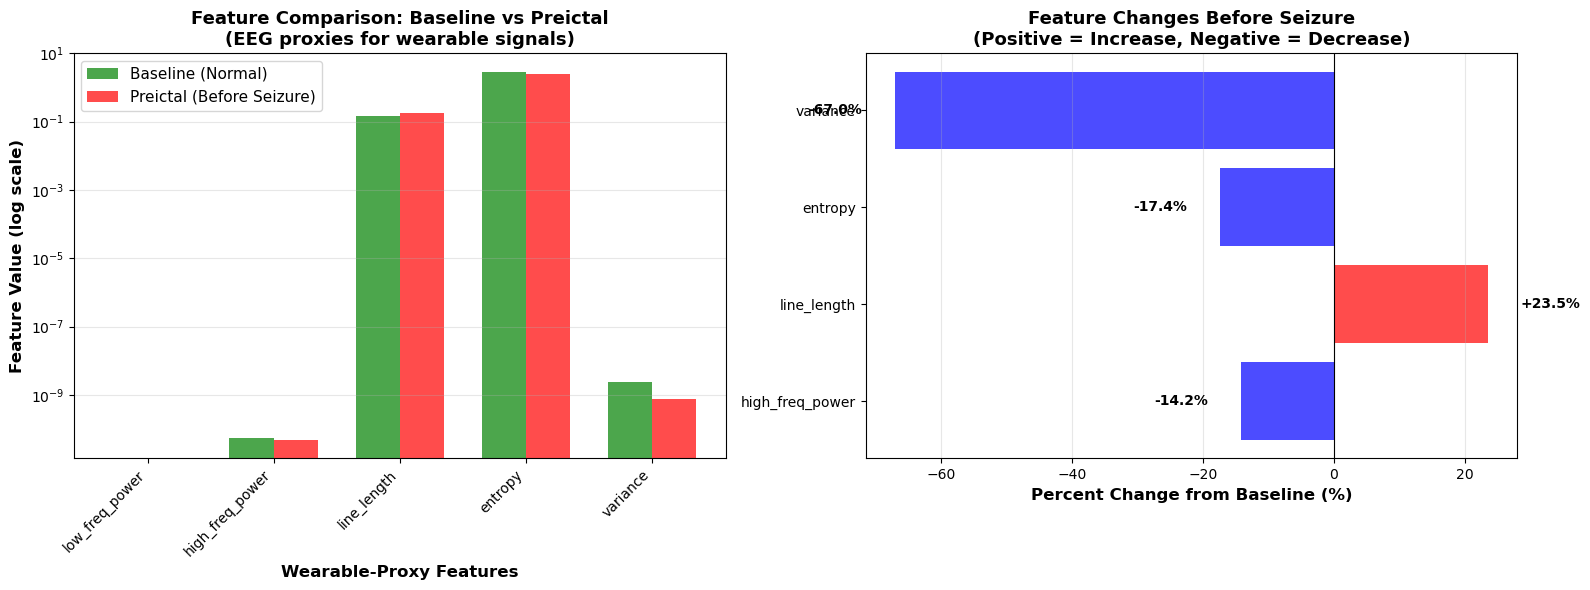



(How much did the features change from baseline to preictal (right before seizure))

Line length - how much the signal travels up and down, correlates with overall physiological activity level, 
state transitions (rest to awake). 
Wearable equivalent is activity counts and step variability. 
(High line length = active brain state, low line length = stable signal = quiet brain state


High frequency power - Fast oscillations, eye blinks, jaw clenching, 
head movement are all high-freq signals. Correlates with movement and muscle activity. 
Wearable equivalent is accelerometer data, and gyroscope (measuring orientation). 
When someone moves, EEG picks up muscle artifacts, high-freq EEG increases when someone moves. 

Entropy is a measure of signal randomness (irregular complex patterns means high entropy). 
Correlates with HRV complexity measures. 

This is just baseline data for one patient (chb-01), first seizure in chb-01_03.edf




In [59]:
import matplotlib.pyplot as plt

print("\n" + "="*60)
print("VISUALIZING FEATURE DIFFERENCES")
print("="*60)

# Prepare data
features = list(baseline_features.keys())
baseline_vals = [baseline_features[f] for f in features]
preictal_vals = [preictal_features[f] for f in features]

# Create comparison plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: Bar chart comparison
x = np.arange(len(features))
width = 0.35

ax = axes[0]
bars1 = ax.bar(x - width/2, baseline_vals, width, 
               label='Baseline (Normal)', color='green', alpha=0.7)
bars2 = ax.bar(x + width/2, preictal_vals, width, 
               label='Preictal (Before Seizure)', color='red', alpha=0.7)

ax.set_xlabel('Wearable-Proxy Features', fontsize=12, fontweight='bold')
ax.set_ylabel('Feature Value (log scale)', fontsize=12, fontweight='bold')
ax.set_title('Feature Comparison: Baseline vs Preictal\n(EEG proxies for wearable signals)', 
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(features, rotation=45, ha='right')
ax.legend(fontsize=11)
ax.set_yscale('log')
ax.grid(True, alpha=0.3, axis='y')

# Right plot: Percent change
ax = axes[1]
pct_changes = []
for feature in features:
    baseline_val = baseline_features[feature]
    preictal_val = preictal_features[feature]
    pct_change = ((preictal_val - baseline_val) / baseline_val) * 100
    pct_changes.append(pct_change)

colors = ['red' if x > 0 else 'blue' for x in pct_changes]
bars = ax.barh(features, pct_changes, color=colors, alpha=0.7)

ax.set_xlabel('Percent Change from Baseline (%)', fontsize=12, fontweight='bold')
ax.set_title('Feature Changes Before Seizure\n(Positive = Increase, Negative = Decrease)', 
             fontsize=13, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
ax.grid(True, alpha=0.3, axis='x')

# Add value labels
for i, (bar, val) in enumerate(zip(bars, pct_changes)):
    ax.text(val + (5 if val > 0 else -5), i, f'{val:+.1f}%', 
            va='center', ha='left' if val > 0 else 'right', fontweight='bold')

plt.tight_layout()
plt.savefig('feature_comparison.png', dpi=150, bbox_inches='tight')
print("✓ Saved: feature_comparison.png")
plt.show()

print("\n" + "="*60)
print("="*60)
print("""
(How much did the features change from baseline to preictal (right before seizure))

Line length - how much the signal travels up and down, correlates with overall physiological activity level, 
state transitions (rest to awake). 
(High line length = active brain state, low line length = stable signal = quiet brain state


High frequency power - Fast oscillations, eye blinks, jaw clenching, 
head movement are all high-freq signals. Correlates with movement and muscle activity. 
Wearable equivalent is accelerometer data, and gyroscope (measuring orientation). 
When someone moves, EEG picks up muscle artifacts, high-freq EEG increases when someone moves. 

Entropy is a measure of signal randomness (irregular complex patterns means high entropy). 
Correlates with HRV complexity measures. 

This is just baseline data for one patient (chb-01), first seizure in chb-01_03.edf

""")
print("="*60)